# 🧪 LAB: Non-linear Dimensionality Reduction — t-SNE and UMAP

Over the past few weeks, we have explored how to handle non-linear relationships, mainly in the context of classification and regression tasks.

However, sometimes the first and most important step is to **visualize** the data — to gain intuition, spot structure, or detect outliers — even before any predictive modeling. You have already seen how PCA can help with this, but as we discussed this week, (ordinary) PCA is a linear method and may not capture non-linear patterns in the data effectively.

In this lab, you will learn about two popular **non-linear dimensionality reduction techniques** that are typically used for **data visualization**:  
- **t-SNE (t-distributed Stochastic Neighbor Embedding)**  
- **UMAP (Uniform Manifold Approximation and Projection)**

You will apply and compare these methods on two datasets:
- A simple biological dataset: Palmer Penguins
- A high-dimensional human genotype dataset from the 1000 Genomes Project (adapted from Diaz-Papkovich *et al.*, 2019)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [ ]:
NAMEs = "Joshua, Ryan, Adalia"

## 1. Background Reading (20 points)

Begin by reading **Section 5.3: t-SNE and UMAP for High-Dimensional Data** from the [*Machine Learning Hero* book](https://www.oreilly.com/library/view/machine-learning-hero/9781837025015/), which is available through UVA’s subscription to O’Reilly.

After reading, discuss with your group and respond to the following questions:

a. **Why might we choose t-SNE or UMAP over PCA for dimensionality reduction?**  
Briefly explain the limitations of PCA, and why non-linear methods like t-SNE and UMAP can be more effective in some contexts.


b. **Summarize the strengths and weaknesses of t-SNE and UMAP.**  
What are the key differences between the two methods? In what situations might you prefer one over the other?

c. **What are the main hyperparameters of each method, and what role do they play?**  
Describe how these hyperparameters affect the behavior and output of the algorithms.


**A. PCA is linear, so it only finds straight-line directions of maximum variance. If the data has curved or non-linear structure, it can squash different clusters together and lose smaller local patterns. t-SNE and UMAP are non-linear and focus on keeping nearby points together instead of preserving variance, so they’re much better at showing clusters in complex data like images or gene expression. UMAP is also faster and keeps more of the overall structure. The downside is that they’re mostly for visualization: cluster distances and sizes don’t mean much, and the results depend a lot on parameters.**


**B.t-SNE is really good at keeping local points together, so you get tight, well-separated clusters. But it’s slow on large datasets, the distances between clusters don’t mean much, and the plot can change a lot with perplexity or the random seed. UMAP keeps local structure too and holds onto more of the global structure. It’s also a lot faster, so it handles much bigger datasets, though it’s sensitive to n_neighbors and min_dist and its plots are just as easy to over-read. The real differences come down to speed and how much global structure each one keeps.**

**C. For t-SNE, the main hyperparameter is perplexity, which is how many neighbors each point pays attention to, usually somewhere between 5 and 50. A low perplexity focuses on very local structure and can break the data into lots of little clusters, while a higher one takes in more of the global picture but can blur the local details. The number of iterations (max_iter) matter too for whether the optimization settles into a clean layout or stops early and looks messy. UMAP’s two main ones are n_neighbors and min_dist. n_neighbors works a lot like perplexity where the small values focus on local detail and larger ones keep more of the global structure, with a default of 15. min_dist defaults to 0.1 and controls how tightly points can be packed in the plot, so a low value gives dense, compact clusters and a higher value spreads things out more evenly.**


## 2. Experiment with the Palmer Penguins Dataset (Toy Example) (50 points)

To get hands-on experience, you will begin by applying dimensionality reduction techniques to a small and interpretable dataset: Palmer Penguins.

Before you begin coding, read the official documentation for the following methods:

- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — from `sklearn.decomposition`
- [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) — from `sklearn.manifold`
- [UMAP](https://umap-learn.readthedocs.io/en/latest/basic_usage.html) — from the `umap-learn` package

After reviewing the documentation, complete the following tasks:

a. Load the Palmer Penguins dataset as demonstrated in the [UMAP documentation](https://umap-learn.readthedocs.io/en/latest/basic_usage.html#penguin-data).  

Select the following numerical features:

- `bill_length_mm`  
- `bill_depth_mm`  
- `flipper_length_mm`  
- `body_mass_g`

Then, **standardize** these features so that each has zero mean and unit variance.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
#Load the penguins dataset
penguins = pd.read_csv("https://raw.githubusercontent.com/allisonhorst/palmerpenguins/c19a904462482430170bfe2c718775ddb7dbb885/inst/extdata/penguins.csv")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [10]:
selected_features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
num_features = penguins[selected_features].dropna()
species = penguins.loc[num_features.index, 'species']
num_features.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [11]:
#import sklearn libraries and umap
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import umap

In [12]:
scaled_num_features = StandardScaler().fit_transform(num_features)
scaled_num_features[:5]

array([[-0.88449874,  0.78544923, -1.41834665, -0.56414208],
       [-0.81112573,  0.1261879 , -1.06225022, -0.50170305],
       [-0.66437972,  0.43046236, -0.42127665, -1.18853234],
       [-1.32473679,  1.08972369, -0.56371522, -0.93877623],
       [-0.84781224,  1.74898502, -0.77737308, -0.68902013]])

b. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the selected features to **2 dimensions**.

Then, for each method:
- Create a **scatter plot** of the 2D projection.
- Use a different color to represent each **species** in the dataset.

This will help you visually assess how well each method separates the species in the reduced space.

*N.B.* You may need to first install `UMAP-learn`. Follow the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html) for that.

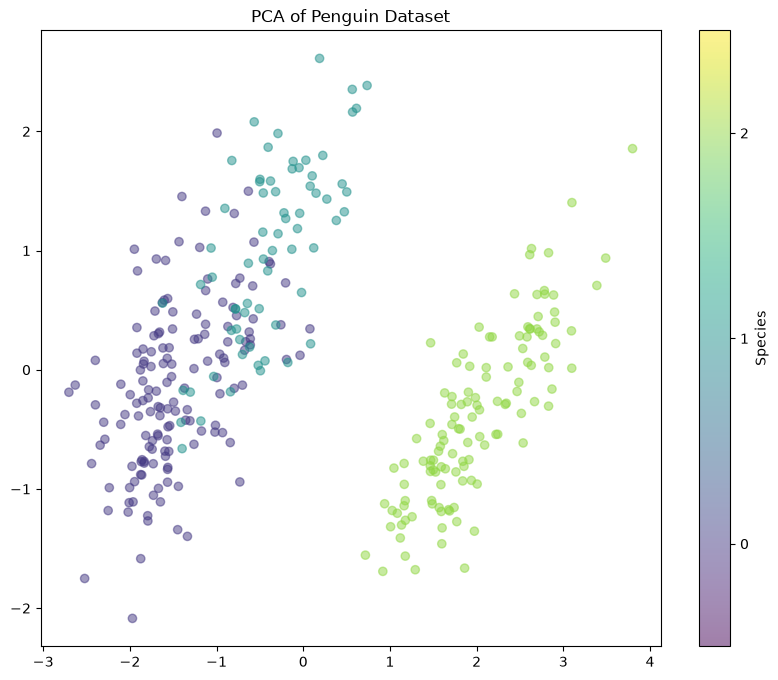

In [37]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_num_features)  

plt.figure(figsize=(10, 8))
plt.scatter(pca_result[:, 0], pca_result[:, 1],
            c=species.astype('category').cat.codes, cmap='viridis', alpha=0.5)
plt.colorbar(ticks=[0, 1, 2], label='Species')
plt.clim(-0.5, 2.5)
plt.title('PCA of Penguin Dataset')
plt.show()



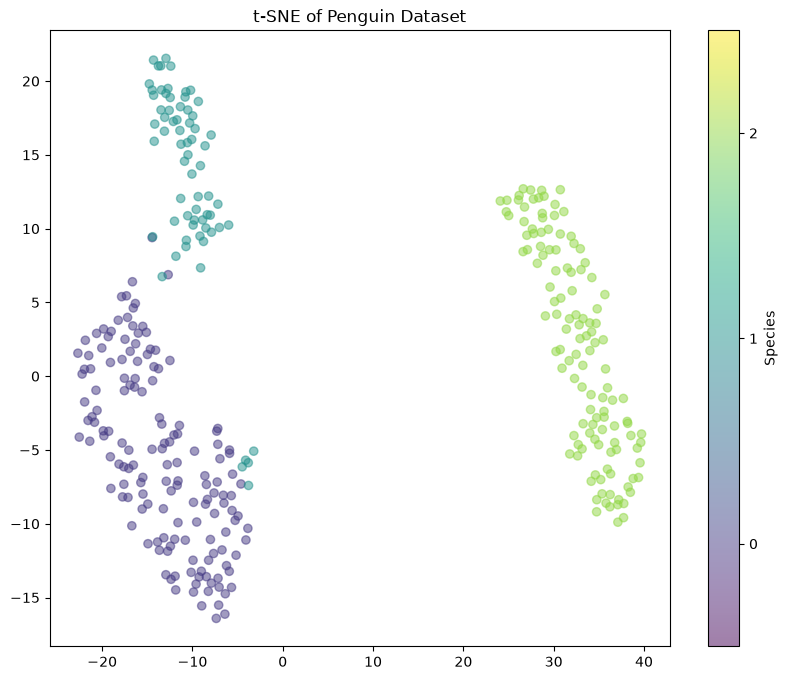

In [38]:
# tsne visualization
tsne = TSNE(n_components=2, random_state=42, perplexity=25)
tsne_result = tsne.fit_transform(scaled_num_features)

plt.figure(figsize=(10, 8))
plt.scatter(tsne_result[:, 0], tsne_result[:, 1],
            c=species.astype('category').cat.codes, cmap='viridis', alpha=0.5)
plt.colorbar(ticks=[0, 1, 2], label='Species')
plt.clim(-0.5, 2.5)
plt.title('t-SNE of Penguin Dataset')
plt.show() 

/Users/joshdetatuva/Desktop/Machine Learning 2/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


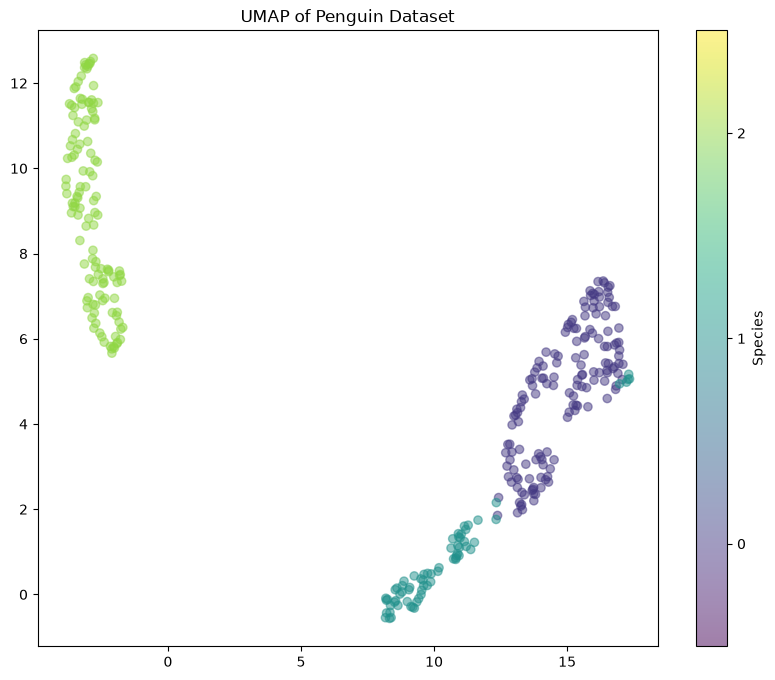

In [36]:
# umap visualization
umap_model = umap.UMAP(n_components=2, random_state=42, n_neighbors=15, min_dist=0.17)
umap_result = umap_model.fit_transform(scaled_num_features) 


plt.figure(figsize=(10, 8))
plt.scatter(umap_result[:, 0], umap_result[:, 1],
            c=species.astype('category').cat.codes, cmap='viridis', alpha=0.5)
plt.colorbar(ticks=[0, 1, 2], label='Species')
plt.clim(-0.5, 2.5)
plt.title('UMAP of Penguin Dataset')
plt.show()  

c. Analyze the resulting plots and describe the main patterns you observe.

- Which method produces the most visually separable clusters?
- Are there any species that overlap in one method but not in others?
- What might explain these differences in how the data is projected?

Elaborate on your observations and compare the strengths and limitations of each method based on this toy example.


**PCA does a good job pulling out species 2, but species 0 and 1 overlap heavily on the left and you can’t really draw a line between them. Both t-SNE (perplexity 25) and UMAP (n_neighbors=15, min_dist=0.17) separate all three species much better. I’d say t-SNE gives the most separable clusters, since species 1 forms its own group at the top with a clear gap from species 0 and only a few teal points get mixed in with the purple ones. UMAP’s clusters are tighter, but species 1 is connected to species 0 by a thin chain of points, and a few teal points end up at the tip of the purple cluster. Species 2 is separate in every plot, so the real difference between the methods is how well they split 0 from 1. PCA looks for the directions with the most overall variance, which here is mostly body size, and that’s where species 2 stands out. Species 0 and 1 are about the same size and differ mainly in things like bill length, so a linear projection squashes that difference. t-SNE and UMAP only care about which points are neighbors, so even a small but consistent difference pulls the two apart. That’s probably also why species 0 breaks into a few sub-blobs and species 2 stretches into a long band in the nonlinear plots. My guess is that it’s male vs. female size differences. On this example, PCA is simple and its axes mean something, so the overlap between 0 and 1 actually tells you they’re similar overall, but it misses the non-linear difference between them. t-SNE gave the cleanest clusters, but the gaps between them don’t mean much and the sub-blobs could change with perplexity or the random seed. UMAP was more compact and kept some of the connection between species 0 and 1, which makes sense since they’re more alike than either is to species 2. With only a few hundred points, UMAP’s speed advantage didn’t really matter here either.**

d. For **t-SNE** and **UMAP**, explore how different hyperparameter settings affect the resulting 2D projections.

- For **t-SNE**, vary the `perplexity` parameter (e.g., 5, 30, 50).
- For **UMAP**, vary the `n_neighbors` parameter (e.g., 5, 15, 50) and optionally `min_dist`.
- Keep `random_state` fixed across all runs so that differences between projections are due primarily to changes in the hyperparameters rather than random initialization.

For each configuration:
- Plot the resulting 2D projection.
- Use color to represent species.

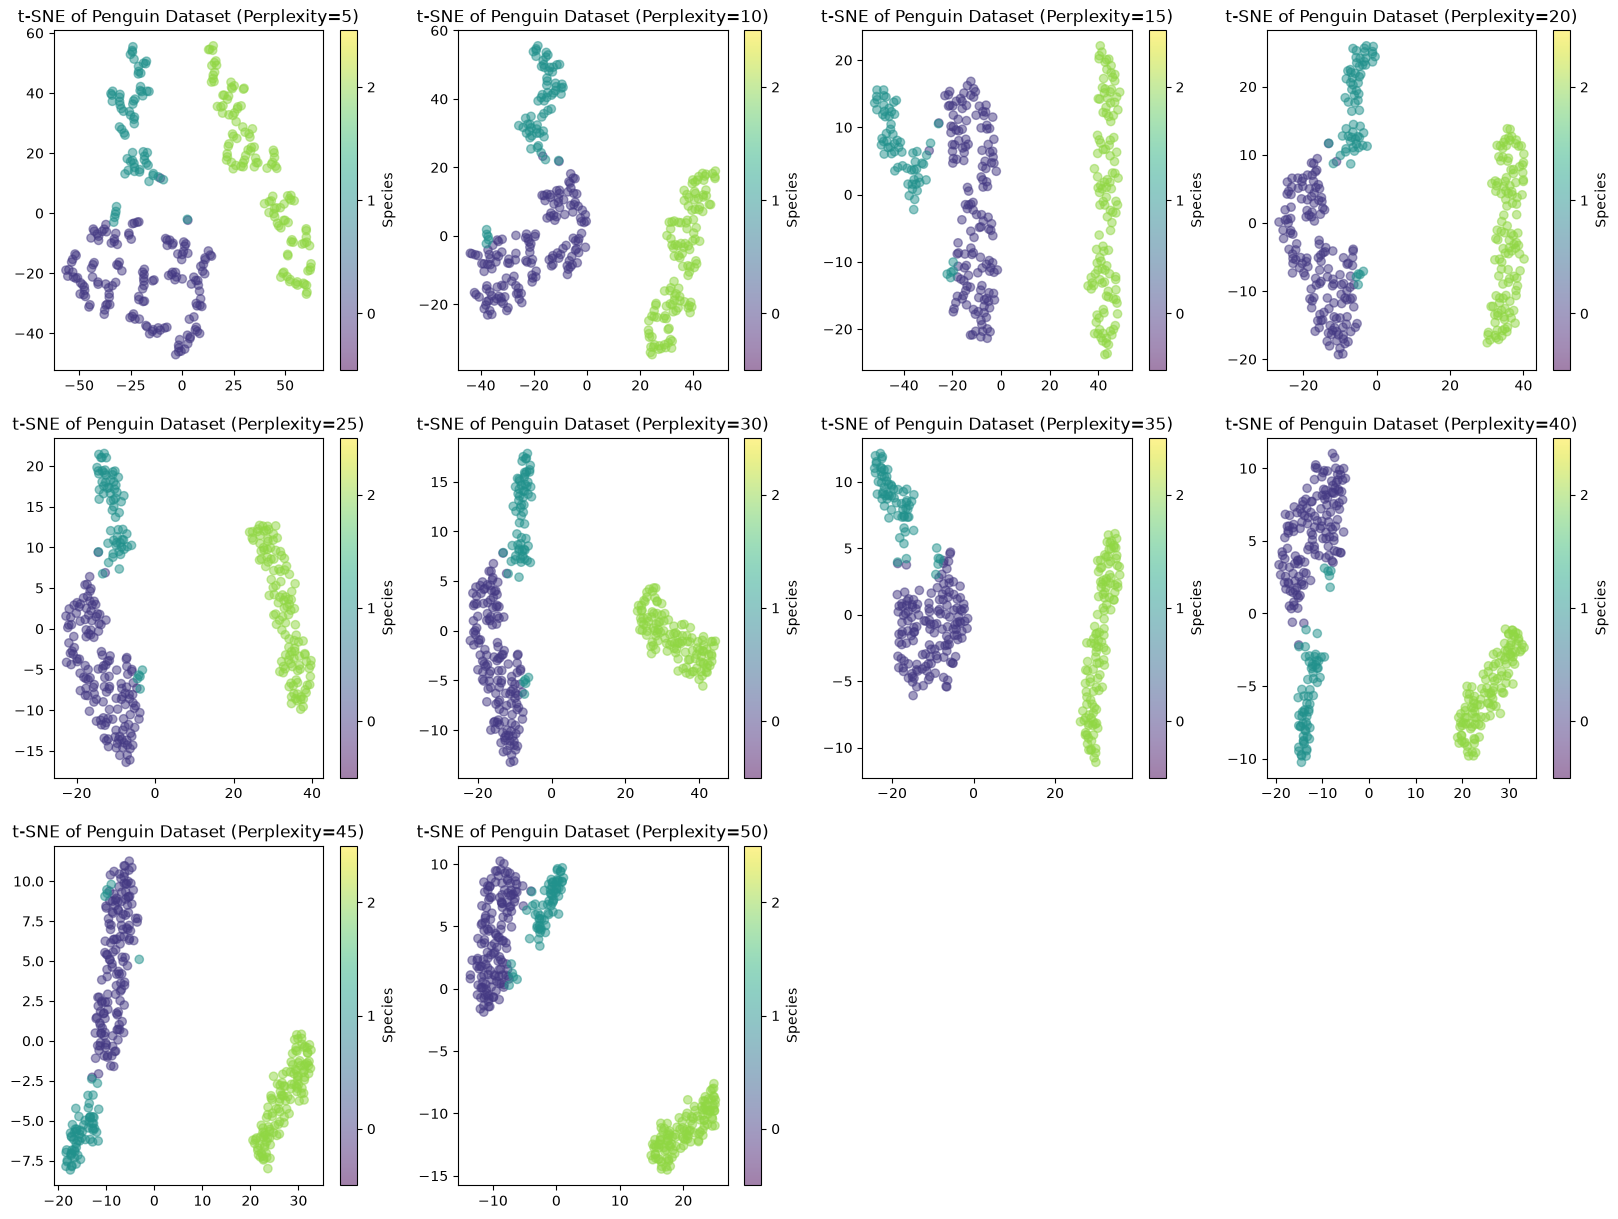

In [ ]:
# TSNE with varying perplexity
perplexities = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
plt.figure(figsize=(20, 15))
for i, perplexity in enumerate(perplexities):
    tsne = TSNE(n_components=2, random_state=42, perplexity=perplexity)
    tsne_result = tsne.fit_transform(scaled_num_features)

    plt.subplot(3, 4, i + 1)
    plt.scatter(tsne_result[:, 0], tsne_result[:, 1],
                c=species.astype('category').cat.codes, cmap='viridis', alpha=0.5)
    plt.colorbar(ticks=[0, 1, 2], label='Species')
    plt.clim(-0.5, 2.5)
    plt.title(f't-SNE of Penguin Dataset (Perplexity={perplexity})')

/Users/joshdetatuva/Desktop/Machine Learning 2/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/joshdetatuva/Desktop/Machine Learning 2/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/joshdetatuva/Desktop/Machine Learning 2/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/joshdetatuva/Desktop/Machine Learning 2/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/joshdetatuva/Desktop/Machine Learning 2/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_stat

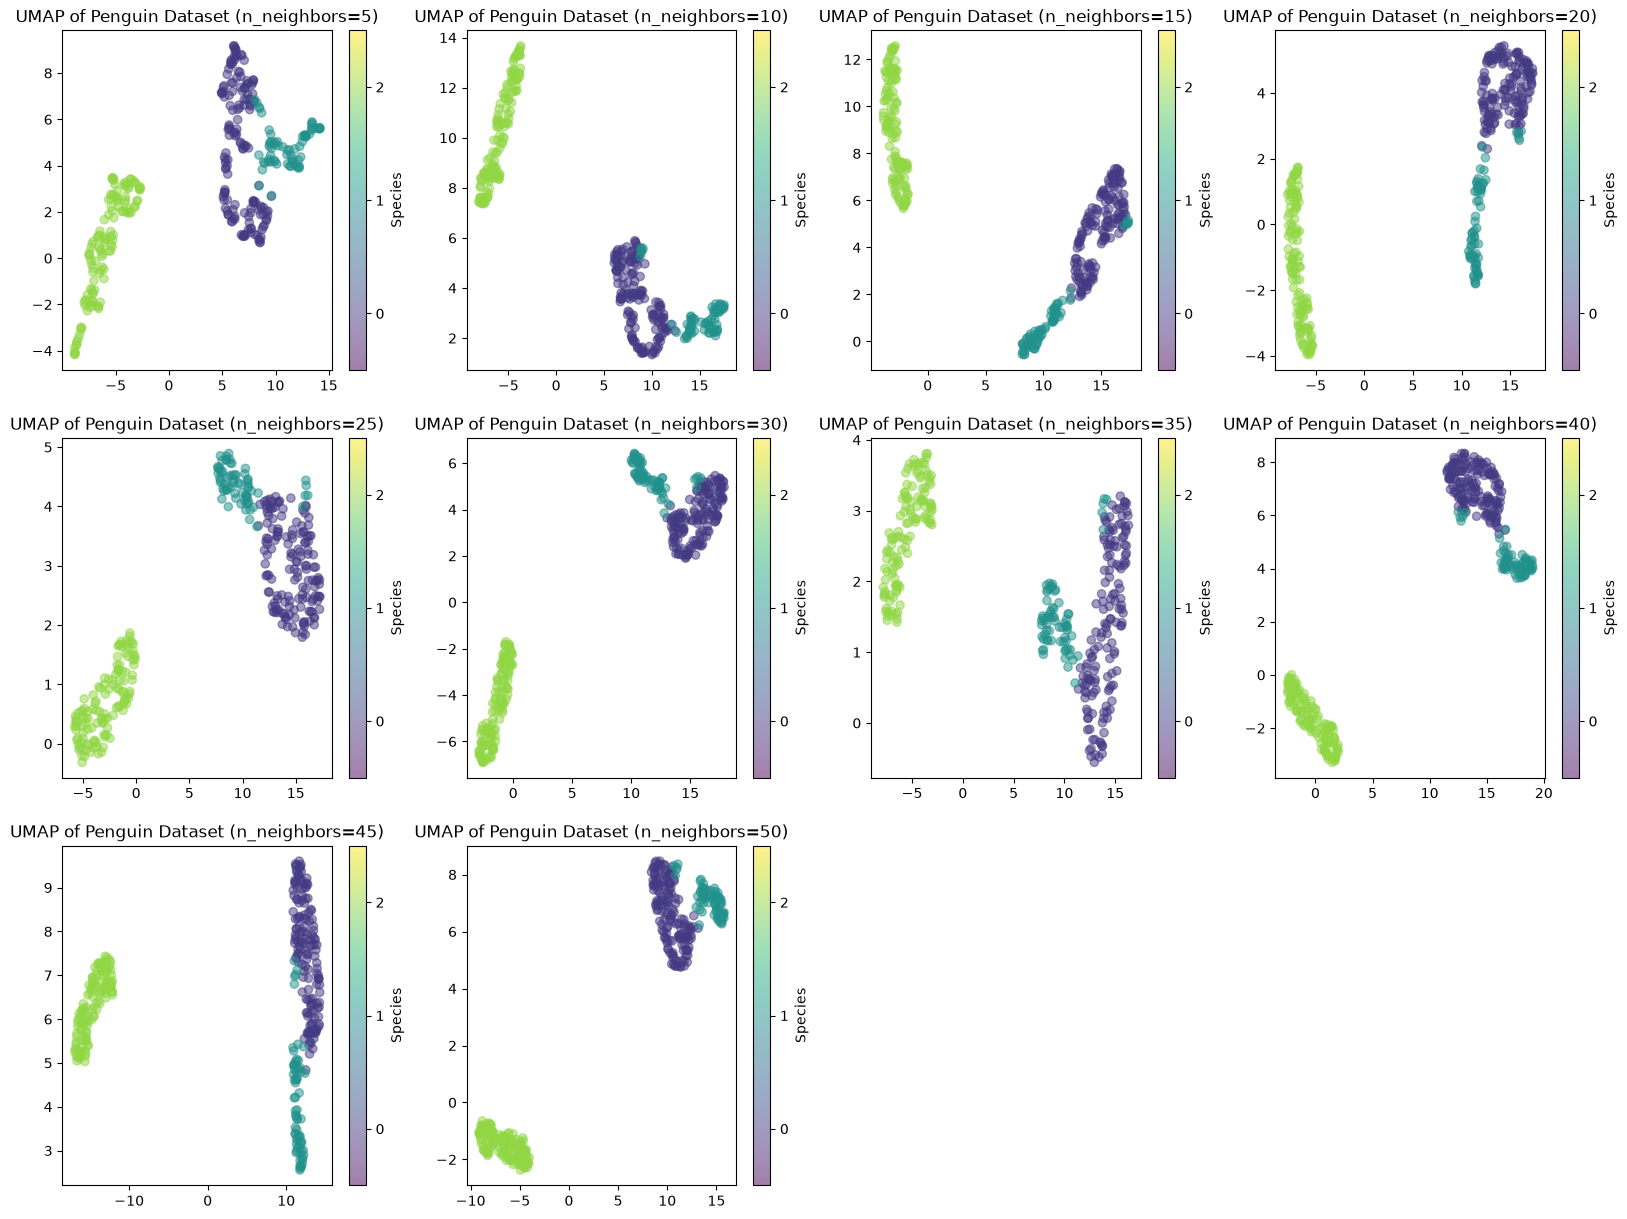

In [44]:
# umap with varying n_neighbors
n_neighbors_list = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
plt.figure(figsize=(20, 15))
for i, n_neighbors in enumerate(n_neighbors_list):
    umap_model = umap.UMAP(n_components=2, random_state=42, n_neighbors=n_neighbors, min_dist=0.17)
    umap_result = umap_model.fit_transform(scaled_num_features)

    plt.subplot(3, 4, i + 1)
    plt.scatter(umap_result[:, 0], umap_result[:, 1],
                c=species.astype('category').cat.codes, cmap='viridis', alpha=0.5)
    plt.colorbar(ticks=[0, 1, 2], label='Species')
    plt.clim(-0.5, 2.5)
    plt.title(f'UMAP of Penguin Dataset (n_neighbors={n_neighbors})')   

After generating the plots, describe the main changes you observe in the visualizations:
- How do the clusters shift, stretch, or separate as hyperparameters change?
- Which settings appear to better preserve the structure of the data?

Elaborate on your observations and support your discussion with specific visual examples.

**As perplexity goes up in t-SNE, the plots go from broken up to smooth and compact. At perplexity 5 everything falls apart into little chains and clumps, spread over axes that run from about -60 to 60 species 2 splits into several separate pieces on the right, species 1 is scattered across the top, and species 0 forms a ring of small clusters at the bottom. By 10 and 15 the pieces start joining into long bands, especially species 2, which turns into one long strip, but species 0 still splits into two sub-blobs and a few teal points end up inside the purple cluster. Around 25 to 40 is where it looks best to me. All three species form clear, separate groups, species 0 finally becomes one solid cluster at 35, and at 40 species 1 sits below species 0 with a clear gap. At 45 and 50, species 1 starts sticking to the end of species 0 again (at 45 it’s basically a continuation of the purple strip), so if perplexity gets too high the 0/1 boundary starts to blur. UMAP does something similar as n_neighbors increases. At 5, species 2 is broken into a chain of small chunks and species 0 is split into an upper and lower half, with species 1 hanging off the side and a few teal points mixed in. At 10 to 20 it gets cleaner species 2 becomes one long band, and species 1 is connected to species 0 only by a thin chain of points, which is easiest to see at 20. From 25 to 50 the clusters get rounder and more compact, but species 0 and 1 merge into one island with species 1 as a lobe on the side, and at 25 and 35 the teal and purple points actually mix where they meet. Species 2 stays completely separate at every setting in both methods, and clusters flipping sides or rotating between plots doesn’t mean anything since the orientation of the layout is arbitrary. The low values (5 to 10) in both methods seem to pick up local noise and create sub-clusters that probably aren’t real. For t-SNE, perplexity around 25 to 40 gave clear species separation without breaking things into fragments. For UMAP, n_neighbors around 15 to 20 separated the species best, while 40 to 50 did a better job showing that species 0 and 1 are much more similar to each other than either one is to species 2, which matches what PCA showed.**

## 3. Apply to Real Data (1000 Genomes Subset) (25 points)

Your goal in this section is to try to create a figure similar to Figure 1 of the Diaz-Papkovich *et al.* (2019) paper, using a subset of genotype data from the 1000 Genomes Project.

To do so, complete the following steps:

a. Load the genotype dataset accompanying this lab, where each row corresponds to an individual, and each column to a genetic variant. Load also the provided population labels for each individual. 

b. **Standardize** the features (i.e., transform the genotype values to have zero mean and unit variance).

c. Apply **PCA**, **t-SNE**, and **UMAP** to reduce the data to 2 dimensions. You may use the default values for the rest of hyperparameters in these techniques. 

d. Create **scatter plots** of the resulting projections, coloring each point according to its **population group**.

e. Reflect on the following questions:
- Explain what you observe in each case. Additionally, which method appears to provide the best visual separation of the population into distinct groups? Elaborate on why this might be the case, based on what you know about each method.
- What changes if you first reduce the data to the **top 25 PCA components**, and then apply t-SNE or UMAP?
- In your opinion, what are the trade-offs between **interpretability** (e.g., preservation of local and global structure) and **performance** (e.g., visual separation of known populations and computational time) when using these dimensionality reduction methods?

Please elaborate on your answers and use the plots to support your discussion.

In [ ]:
# YOUR CODE HERE

## 4. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE